# 04 · Problem framing and feature engineering

**Data science step 4 of 7:** decide exactly what to predict, and build the inputs (features) for it.

**Input:** `data/processed/stops.parquet` (from notebook 03)
**Output:** `examples_dev.parquet` and `examples_final.parquet`, model-ready tables

## The question
> A train has just reached a station, and we know how late it is. **How late will it be at its final destination?**

This is an **ETA** (estimated time of arrival), the number a passenger or a control room needs.

## One example = one (journey, current stop)
For each journey, every stop **except the destination** becomes one example:
- **Features (inputs):** only what is known *when the train reaches that stop*
- **Target (answer):** the arrival delay at the destination

A journey with 25 stops gives 24 examples, all with the same target, each seen from a different point in the trip.

## Rules against leakage
**Target leakage** = the model uses information it wouldn't have in real life. Then it looks great in testing and fails in reality.
1. **Nothing from later in the same journey.** At stop 5 we don't know the delay at stop 6.
2. **Nothing from the future.** "This train usually loses 20 minutes after Nagpur" may only come from **earlier dates**.
3. **No row may see its own answer** (see *out-of-fold*, Step 5).

In [1]:
import re
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

DATA = Path("data/processed")
FIGURES = Path("reports/figures")

stops = pd.read_parquet(DATA / "stops.parquet")
print(f"{len(stops):,} stops, {stops['trip_id'].nunique():,} trips")

1,282,263 stops, 57,485 trips


## Step 1: The target, the delay at the destination
Find each trip's destination delay, then copy it onto every row of that trip.

In [2]:
dest_delay = stops.loc[stops["is_destination"]].set_index("trip_id")["delay"]
stops["target"] = stops["trip_id"].map(dest_delay)

stops.loc[stops["trip_id"] == "12303_2024-09-02", ["station", "stop_no", "delay", "target"]].head(5)

,station,stop_no,delay,target
267180,HWH,1,0.0,0.0
267181,BWN,2,15.0,0.0
267182,DGR,3,3.0,0.0
267183,ASN,4,2.0,0.0
267184,CRJ,5,4.0,0.0


Every row of this journey has `target = 0`: Poorva Express reached New Delhi on time that day.

## Step 2: Features

### 2a. Delay so far
| Feature | Meaning |
|---|---|
| `cur_delay` | delay at this stop (the most important input) |
| `prev_delay` | delay at the previous stop with a known value |
| `delay_change` | `cur_delay − prev_delay`: is the train losing or gaining time right now? |
| `origin_delay` | delay at the first station |
| `max_delay_so_far` | the worst delay so far in this journey |

In [3]:
by_trip = stops.groupby("trip_id")

stops["cur_delay"] = stops["delay"]
stops["prev_delay"] = by_trip["delay"].shift().groupby(stops["trip_id"]).ffill()
stops["delay_change"] = stops["cur_delay"] - stops["prev_delay"]

origin = stops.loc[stops["stop_no"] == 1].set_index("trip_id")["delay"]
stops["origin_delay"] = stops["trip_id"].map(origin)

# cummax = running maximum. NaN (unknown) is temporarily -1 so it doesn't break the running max.
stops["max_delay_so_far"] = stops["delay"].fillna(-1).groupby(stops["trip_id"]).cummax().replace(-1, np.nan)

stops.loc[stops["trip_id"] == "12303_2024-09-02",
          ["station", "cur_delay", "prev_delay", "delay_change", "origin_delay", "max_delay_so_far"]].head(8)

,station,cur_delay,prev_delay,delay_change,origin_delay,max_delay_so_far
267180,HWH,0.0,NaN,NaN,0.0,0.0
267181,BWN,15.0,0.0,15.0,0.0,15.0
267182,DGR,3.0,15.0,-12.0,0.0,15.0
267183,ASN,2.0,3.0,-1.0,0.0,15.0
267184,CRJ,4.0,2.0,2.0,0.0,15.0
267185,JMT,2.0,4.0,-2.0,0.0,15.0
267186,MDP,2.0,2.0,0.0,0.0,15.0
267187,JSME,0.0,2.0,-2.0,0.0,15.0


### 2b. Position in the journey
| Feature | Meaning |
|---|---|
| `stop_no`, `stops_left` | how many stops done / still to go |
| `km_done`, `km_left` | distance done / still to go |
| `share_done` | fraction of the route completed (0 → 1), from Challenge 3 |

In [4]:
stops["stops_left"] = stops["n_stops"] - stops["stop_no"]
stops["km_done"] = stops["distance"]
stops["km_left"] = stops["total_km"] - stops["distance"]
stops["share_done"] = stops["distance"] / stops["total_km"]

### 2c. Timetable
| Feature | Meaning |
|---|---|
| `sched_min_left` | scheduled minutes still to go |
| `planned_kmh_left` | planned speed for the rest of the trip. **A slow planned speed = padding**, so more time to recover |
| `total_km`, `n_stops` | size of the whole route |
| `hour` | scheduled hour at this stop (0–23) |
| `dow` | day of the week (0 = Monday) |

In [5]:
stops["sched_min_left"] = stops["total_sched_min"] - stops["sched_min"]
hours_left = stops["sched_min_left"].where(stops["sched_min_left"] > 0) / 60
stops["planned_kmh_left"] = (stops["km_left"] / hours_left).clip(upper=200)

stops["hour"] = pd.to_datetime(stops["sch_arr"], format="%I:%M %p").dt.hour
stops["dow"] = stops["date"].dt.dayofweek

### 2d. Train and region
| Feature | Meaning |
|---|---|
| `zone` | railway zone of this station (Challenge 2: KRCL worst, ER best) |
| `is_special` | train number starts with 0 = special/festival train |
| `train_type` | from the train name: Rajdhani, Vande Bharat, superfast, local, … |

In [6]:
TRAIN_TYPES = [  # checked in this order, the first match wins
    ("special", r"special|spl|festval"),
    ("vande_bharat", r"vande ?bharat"),
    ("rajdhani", r"rajdhani"),
    ("jan_shatabdi", r"jan ?shatabdi"),
    ("shatabdi", r"shatabdi"),
    ("duronto", r"duronto"),
    ("humsafar", r"humsafar|humsfr"),
    ("garib_rath", r"garib ?rath"),
    ("local", r"memu|demu|passenger|local"),
    ("superfast", r"\bsf\b|\bsuf\b|superfast"),
]


def train_type(name):
    name = name.lower()
    for label, pattern in TRAIN_TYPES:
        if re.search(pattern, name):
            return label
    return "express"


stops["is_special"] = stops["train"].str.startswith("0").astype(int)
types = {name: train_type(name) for name in stops["train_name"].unique()}
stops["train_type"] = stops["train_name"].map(types)

# 'category' = a fixed list of allowed text values. Set on the full table so train and test encode them identically.
stops["zone"] = stops["zone"].astype("category")
stops["train_type"] = stops["train_type"].astype("category")

stops["train_type"].value_counts()

train_type
express         1005261
superfast        107655
special           76895
local             37542
vande_bharat      18251
jan_shatabdi      11586
rajdhani           6426
garib_rath         6064
humsafar           4863
shatabdi           4844
duronto            2876
Name: count, dtype: int64

## Step 3: Keep only usable examples
- not the destination itself (there's nothing left to predict)
- the current delay is known (not a fake zero)
- the destination delay is known

In [7]:
usable = ~stops["is_destination"] & stops["cur_delay"].notna() & stops["target"].notna()
examples = stops[usable].reset_index(drop=True)
print(f"{len(examples):,} examples from {examples['trip_id'].nunique():,} trips")

1,099,443 examples from 53,442 trips


## Step 4: Split by date (train / valid / test)

| Split | Journey dates | Used for |
|---|---|---|
| **train** | Sept 1–20 | the model learns from these |
| **valid** | Sept 21–25 | comparing models and choosing settings |
| **test** | Sept 26–30 | **one final score**, used once at the very end |

**Why not a random split?** A random split would put stop 5 of a journey in *train* and stop 6 of the **same journey** in *test*. They share the same target, so the model would be graded on answers it has already seen. Splitting by date matches real life: learn from the past, predict the future.

In [8]:
examples["split"] = np.select(
    [examples["date"] <= "2024-09-20", examples["date"] <= "2024-09-25"],
    ["train", "valid"],
    default="test",
)
examples.groupby("split").agg(rows=("trip_id", "size"), trips=("trip_id", "nunique"),
                              first_date=("date", "min"), last_date=("date", "max"))

,rows,trips,first_date,last_date
split,,,,
test,187674,9110,2024-09-26,2024-09-30
train,729385,35380,2024-09-01,2024-09-20
valid,182384,8952,2024-09-21,2024-09-25


## Step 5: History features (learned from past journeys)

| Feature | Meaning |
|---|---|
| `hist_change` | median change in delay **from this station to the destination**, for **this train**, in past journeys |
| `hist_train_dest` | this train's median destination delay in past journeys |
| `hist_station_gain` | median delay added on the way into this station, over all trains |
| `hist_n_trips` | how many past journeys these statistics are based on |

`hist_change` is the most useful, but it's computed **from the target**, so it can leak.

### Out-of-fold: no row sees its own answer
- **valid/test rows:** statistics come from the training dates (the past). ✅
- **train rows:** using all training dates would include the row's **own** journey, which means its own answer. Instead the 20 training days are split into 5 groups, and each group gets statistics computed **only from the other 4 groups**.

In [9]:
examples["change_to_dest"] = examples["target"] - examples["cur_delay"]   # only used to build hist_change


def median_lookup(fit, apply, keys, col):
    # Median of `col` per group in `fit`, looked up for every row of `apply`.
    stats = fit.groupby(keys)[col].median().rename("value").reset_index()
    return apply[keys].merge(stats, on=keys, how="left")["value"].to_numpy()


def history(fit, apply):
    # History features for the rows in `apply`, learned only from the rows in `fit`.
    fit_trips = fit.drop_duplicates("trip_id")
    out = pd.DataFrame(index=apply.index)
    out["hist_change"] = median_lookup(fit, apply, ["train", "station"], "change_to_dest")
    out["hist_train_dest"] = median_lookup(fit_trips, apply, ["train"], "target")
    out["hist_station_gain"] = median_lookup(fit, apply, ["station"], "delay_change")
    counts = fit_trips.groupby("train").size().rename("value").reset_index()
    out["hist_n_trips"] = apply[["train"]].merge(counts, on="train", how="left")["value"].fillna(0).to_numpy()
    return out


def add_history(examples, fit_splits, n_folds=5):
    ex = examples.copy()
    is_fit = ex["split"].isin(fit_splits)
    fit_rows = ex[is_fit]

    parts = [history(fit_rows, ex[~is_fit])]                  # other splits: learn from all fit rows
    fit_dates = np.sort(fit_rows["date"].unique())
    for fold_dates in np.array_split(fit_dates, n_folds):     # fit rows: out-of-fold
        held_out = fit_rows["date"].isin(fold_dates)
        parts.append(history(fit_rows[~held_out], fit_rows[held_out]))

    hist = pd.concat(parts).loc[ex.index]
    for col in hist.columns:
        ex[col] = hist[col]
    return ex

We build **two versions**:
- **`dev`**: history learned from **train** dates. Used in notebooks 05–06 to compare models on **valid**.
- **`final`**: history learned from **train + valid** dates. Used in notebook 07 for the final model and the **test** score.

In [10]:
dev = add_history(examples, fit_splits=["train"])
final = add_history(examples, fit_splits=["train", "valid"])

dev.loc[dev["split"] == "valid", ["train", "station", "cur_delay", "hist_change", "hist_train_dest", "target"]].head(8)

,train,station,cur_delay,hist_change,hist_train_dest,target
10,00961,MJ,4.0,0.0,0.0,29.0
11,00961,FLD,15.0,0.0,0.0,29.0
26,00962,KBK,5.0,3.0,4.0,0.0
27,00962,FLD,0.0,-9.0,4.0,0.0
436,01023,PUNE,0.0,-5.0,0.0,0.0
437,01023,SSV,0.0,-5.0,0.0,0.0
438,01023,JJR,0.0,-13.0,0.0,0.0
439,01023,NIRA,0.0,-14.0,0.0,0.0


How to read a row: train 01023 at station SSV is on time (0). In the past, from SSV to its destination, this train **gained** a median of 5 minutes (`hist_change = -5`). The real destination delay was 0.

## Step 6: Look at the final feature table

In [11]:
NUMERIC_FEATURES = [
    "cur_delay", "prev_delay", "delay_change", "origin_delay", "max_delay_so_far",
    "stop_no", "stops_left", "km_done", "km_left", "share_done",
    "sched_min_left", "planned_kmh_left", "total_km", "n_stops", "hour", "dow", "is_special",
    "hist_change", "hist_train_dest", "hist_station_gain", "hist_n_trips",
]
CATEGORICAL_FEATURES = ["zone", "train_type"]
FEATURES = NUMERIC_FEATURES + CATEGORICAL_FEATURES

print(len(FEATURES), "features")
dev[NUMERIC_FEATURES + ["target"]].describe().T.round(1)

23 features


,count,mean,std,min,25%,50%,75%,max
cur_delay,1099443.0,30.0,77.4,0.0,0.0,8.0,27.0,2931.0
prev_delay,1046001.0,29.8,76.5,0.0,0.0,8.0,27.0,2931.0
delay_change,1046001.0,1.3,17.7,-2909.0,-2.0,0.0,4.0,2910.0
origin_delay,1099443.0,8.7,43.9,0.0,0.0,0.0,2.0,1451.0
max_delay_so_far,1099443.0,46.2,82.0,0.0,12.0,26.0,49.0,2931.0
stop_no,1099443.0,15.7,13.7,1.0,6.0,12.0,22.0,118.0
stops_left,1099443.0,15.8,13.8,1.0,6.0,12.0,22.0,118.0
km_done,1099443.0,479.2,511.7,0.0,119.0,307.0,656.0,4137.0
km_left,1099443.0,521.0,522.7,1.0,152.0,347.0,705.0,4162.0
share_done,1099443.0,0.5,0.3,0.0,0.2,0.5,0.7,1.0


In [12]:
missing = dev[FEATURES].isna().mean().mul(100).round(1)
missing[missing > 0].rename("% missing")

prev_delay           4.9
delay_change         4.9
planned_kmh_left     1.4
hist_change          1.0
hist_train_dest      1.0
hist_station_gain    1.2
Name: % missing, dtype: float64

A few features are sometimes missing: the first stop has no `prev_delay`, and trains that never ran on training dates have no history. Gradient boosting handles `NaN` by itself; for linear regression we'll fill them in notebook 06.

## Step 7: The target is unusual

median 0 min | mean 31.8 min | 66% exactly 0 | max 1822 min


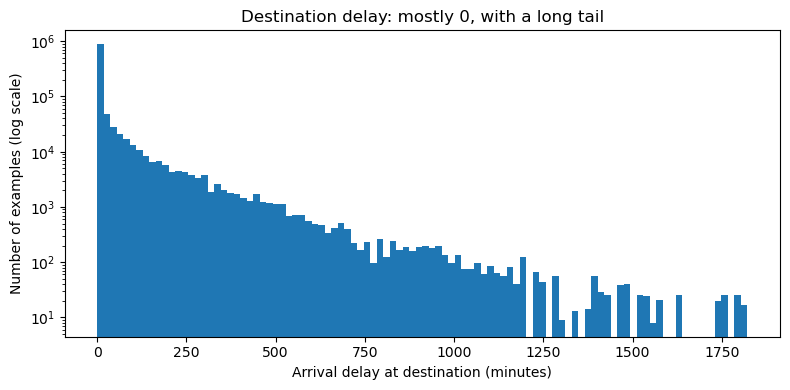

In [13]:
y = dev["target"]
print(f"median {y.median():.0f} min | mean {y.mean():.1f} min | {100 * (y == 0).mean():.0f}% exactly 0 | max {y.max():.0f} min")

fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(y, bins=100)
ax.set_yscale("log")
ax.set_title("Destination delay: mostly 0, with a long tail")
ax.set_xlabel("Arrival delay at destination (minutes)")
ax.set_ylabel("Number of examples (log scale)")
plt.tight_layout()
plt.show()

Why so many zeros? Challenge 3 again, now on the cleaned data:

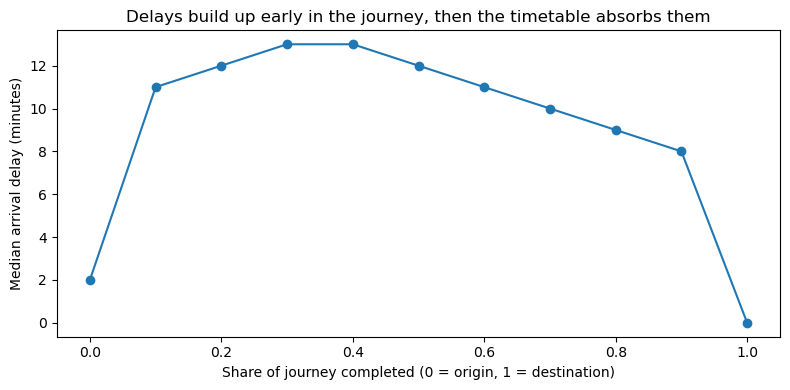

In [14]:
share = (stops["distance"] / stops["total_km"]).round(1)

fig, ax = plt.subplots(figsize=(8, 4))
stops.groupby(share)["delay"].median().plot(marker="o", ax=ax)
ax.set_title("Delays build up early in the journey, then the timetable absorbs them")
ax.set_xlabel("Share of journey completed (0 = origin, 1 = destination)")
ax.set_ylabel("Median arrival delay (minutes)")
plt.tight_layout()
plt.savefig(FIGURES / "delay_along_journey.png", dpi=120)
plt.show()

**66% of targets are exactly 0** because of schedule padding (Challenge 3). That shape matters a lot when choosing a model's loss function (notebook 06).

## Step 8: Save

In [15]:
keep = ["trip_id", "train", "date", "station", "split", "target"] + FEATURES
dev[keep].to_parquet(DATA / "examples_dev.parquet", index=False)
final[keep].to_parquet(DATA / "examples_final.parquet", index=False)
print("saved examples_dev.parquet and examples_final.parquet:", dev[keep].shape)

saved examples_dev.parquet and examples_final.parquet: (1099443, 29)


## Summary
- **Task:** predict the destination delay from any stop of the journey (ETA)
- **1,099,443 examples** with **23 features**, split **by date**: train 729k / valid 182k / test 188k
- History features are **out-of-fold**, so no row sees its own answer

**Next:** notebook 05, simple baselines and how we measure performance.

### 🧠 Try it yourself
1. Build the **leaky** version of `hist_change`: `train_rows = examples[examples["split"] == "train"]`, then `history(train_rows, train_rows)`. Which is closer to each row's real `change_to_dest`, leaky or out-of-fold? Why is that a problem, not a strength?
2. Invent one new feature (e.g. "has the delay grown at each of the last 3 stops?"). Add it and see in notebook 06 whether it helps.
3. Why is `stops_left` not the same information as `km_left`? Find two trains where they disagree a lot.